# GĐ 2: THỐNG KÊ MÔ TẢ (Descriptive Statistics)

**Mục tiêu:** mô tả đặc điểm của biến Y (`pm25`) và các biến X (`temperature`, `humidity`, `wind`, `rain`) — làm nền cho GĐ 3 (kiểm định, hồi quy).

## Đọc dữ liệu

Dùng đúng file `aqi_hcm_daily.csv` 
- `matplotlib.pyplot` → vẽ biểu đồ (histogram, boxplot)
- `scipy.stats` → có sẵn hàm tính skewness, kurtosis (không phải tự viết công thức tay)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline

df = pd.read_csv("../01_Data/aqi_hcm_daily.csv", parse_dates=["date"])
print(f"Da doc {len(df)} dong, {df.shape[1]} cot")
df.head()

Da doc 629 dong, 16 cot


,date,pm25,pm25_cov,temperature,temperature_cov,humidity,humidity_cov,wind,rain,month,dow,mua,nang,aqi_cat,pbl_sang_m,ap_suat
0,2024-11-19,31.2,29.0,28.8,29.0,57.9,29.0,8.9,0.9,11,1,Mua kho,0,Trung binh,110.714286,1008.6
1,2024-11-20,36.6,100.0,28.9,100.0,54.1,100.0,13.0,1.4,11,2,Mua kho,1,Kem (nhay cam),82.142857,1008.3
2,2024-11-21,42.2,100.0,28.9,100.0,53.5,100.0,8.7,5.9,11,3,Mua kho,1,Kem (nhay cam),137.142857,1007.7
3,2024-11-22,38.2,100.0,28.8,100.0,54.1,100.0,8.9,0.5,11,4,Mua kho,1,Kem (nhay cam),80.714286,1007.9
4,2024-11-23,37.1,100.0,28.5,100.0,53.7,100.0,10.0,0.3,11,5,Mua kho,1,Kem (nhay cam),100.000000,1008.5


## 1. Xu hướng trung tâm — Mean / Median / Mode

- **Mean** (trung bình cộng) → nhạy với giá trị cực đoan (outlier kéo mean lệch theo)
- **Median** (trung vị) → giá trị đứng giữa khi sắp xếp tăng dần → KHÔNG bị outlier kéo lệch
- **Mode** (yếu vị) → giá trị xuất hiện nhiều lần nhất

**Vì sao so sánh mean với median lại quan trọng?** Nếu `mean > median` rõ rệt → phân phối **lệch phải** (có vài ngày ô nhiễm cực nặng kéo trung bình lên cao, dù đa số ngày ở mức vừa phải). Đây là dấu hiệu quen thuộc với PM2.5 — ô nhiễm cực nặng hiếm khi xảy ra nhưng khi xảy ra thì rất cao.

In [4]:
mean_pm25 = df.pm25.mean()
median_pm25 = df.pm25.median()
mode_pm25 = df.pm25.mode()[0]   # mode() tra ve 1 Series (co the co nhieu mode) -> lay gia tri dau tien

print("THONG KE XU HUONG TRUNG TAM - PM2.5")
print("-" * 50)
print(f"Mean   : {mean_pm25:.2f} ug/m3")
print(f"Median : {median_pm25:.2f} ug/m3")
print(f"Mode   : {mode_pm25:.2f} ug/m3")
print()
if mean_pm25 > median_pm25:
    print(f"Mean > Median (chenh {mean_pm25 - median_pm25:.2f}) -> phan phoi LECH PHAI")
    print("  => Da so ngay o muc vua phai, nhung co vai ngay o nhiem rat nang keo mean len cao")
elif mean_pm25 < median_pm25:
    print(f"Mean < Median -> phan phoi LECH TRAI")
else:
    print("Mean = Median -> phan phoi doi xung")

THONG KE XU HUONG TRUNG TAM - PM2.5
--------------------------------------------------
Mean   : 32.41 ug/m3
Median : 30.30 ug/m3
Mode   : 29.20 ug/m3

Mean > Median (chenh 2.11) -> phan phoi LECH PHAI
  => Da so ngay o muc vua phai, nhung co vai ngay o nhiem rat nang keo mean len cao


## 2. Độ phân tán — Range / IQR / Variance / Std / CV

- **Range** = max − min → khoảng trải rộng toàn bộ, nhưng nhạy outlier
- **IQR** = Q3 − Q1 → độ trải rộng của 50% dữ liệu "giữa", không bị outlier ảnh hưởng
- **Variance (phương sai)** = trung bình bình phương độ lệch so với mean → đơn vị bị bình phương (µg²/m⁶), khó đọc trực tiếp
- **Std (độ lệch chuẩn)** = căn bậc 2 của variance → đưa về đúng đơn vị gốc (µg/m³), dễ đọc hơn variance
- **CV (hệ số biến thiên)** = std / mean × 100% → đo độ phân tán **tương đối**, dùng để so sánh mức độ dao động giữa các biến có đơn vị khác nhau (vd so `pm25` với `wind`)

In [5]:
pm25 = df.pm25

rng = pm25.max() - pm25.min()
q1, q3 = pm25.quantile([.25, .75])
iqr = q3 - q1
var = pm25.var()      # phuong sai mau (ddof=1 mac dinh trong pandas)
std = pm25.std()       # can bac 2 cua var
cv = std / pm25.mean() * 100

print("THONG KE DO PHAN TAN - PM2.5")
print("-" * 50)
print(f"Min - Max        : {pm25.min():.1f} - {pm25.max():.1f} ug/m3")
print(f"Range            : {rng:.2f} ug/m3")
print(f"Q1 - Q3          : {q1:.1f} - {q3:.1f} ug/m3")
print(f"IQR              : {iqr:.2f} ug/m3")
print(f"Variance         : {var:.2f} (ug/m3)^2")
print(f"Std (do lech chuan): {std:.2f} ug/m3")
print(f"CV (he so bien thien): {cv:.1f}%")

THONG KE DO PHAN TAN - PM2.5
--------------------------------------------------
Min - Max        : 12.9 - 92.8 ug/m3
Range            : 79.90 ug/m3
Q1 - Q3          : 24.6 - 38.9 ug/m3
IQR              : 14.30 ug/m3
Variance         : 129.96 (ug/m3)^2
Std (do lech chuan): 11.40 ug/m3
CV (he so bien thien): 35.2%


## 3. Hình dạng phân phối — Skewness / Kurtosis

Nhắc lại bản chất (đã học ở Lab01):
- **Skewness (độ lệch)**: `> 0` lệch phải (đuôi dài bên phải), `< 0` lệch trái, `≈ 0` đối xứng
- **Kurtosis (độ nhọn)**: `> 0` nhọn hơn phân phối chuẩn (nhiều giá trị tập trung gần mean + đuôi dày hơn), `< 0` bẹt hơn phân phối chuẩn

`scipy.stats.skew` / `.kurtosis` tính đúng công thức đã học (kurtosis mặc định là **excess kurtosis**, tức đã trừ đi 3 — phân phối chuẩn cho ra 0, không phải 3).

In [6]:
skew_pm25 = stats.skew(pm25)
kurt_pm25 = stats.kurtosis(pm25)   # excess kurtosis: phan phoi chuan -> 0

print("HINH DANG PHAN PHOI - PM2.5")
print("-" * 50)
print(f"Skewness : {skew_pm25:.3f}  "
      f"({'LECH PHAI' if skew_pm25 > 0 else 'LECH TRAI' if skew_pm25 < 0 else 'DOI XUNG'})")
print(f"Kurtosis : {kurt_pm25:.3f}  "
      f"({'NHON hon chuan' if kurt_pm25 > 0 else 'BET hon chuan' if kurt_pm25 < 0 else 'GIONG chuan'})")

HINH DANG PHAN PHOI - PM2.5
--------------------------------------------------
Skewness : 1.140  (LECH PHAI)
Kurtosis : 2.011  (NHON hon chuan)


## 4. Trực quan hoá — Histogram + Boxplot

Nhìn bằng mắt để xác nhận lại những gì vừa tính bằng số — histogram cho thấy hình dạng phân phối, boxplot cho thấy rõ outlier (các chấm nằm ngoài 2 "râu").

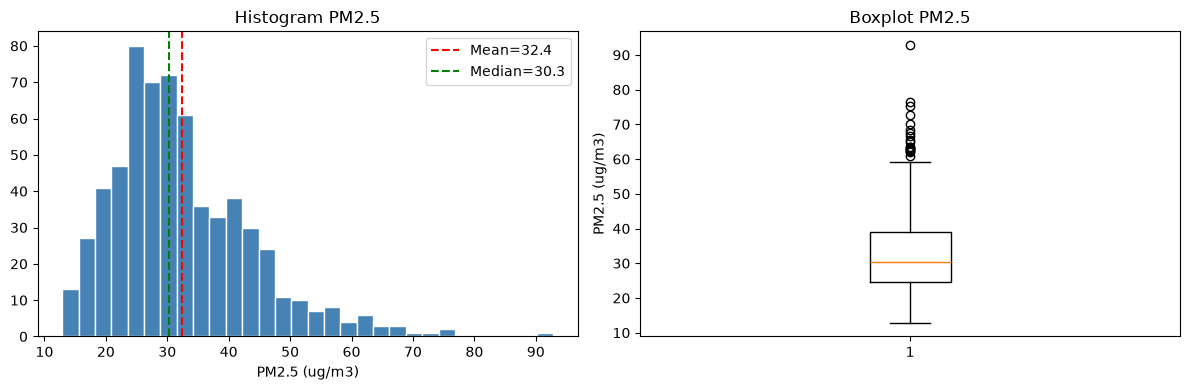

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(pm25, bins=30, color="steelblue", edgecolor="white")
ax1.axvline(mean_pm25, color="red", linestyle="--", label=f"Mean={mean_pm25:.1f}")
ax1.axvline(median_pm25, color="green", linestyle="--", label=f"Median={median_pm25:.1f}")
ax1.set_title("Histogram PM2.5")
ax1.set_xlabel("PM2.5 (ug/m3)")
ax1.legend()

ax2.boxplot(pm25)   # mac dinh la bieu do doc
ax2.set_title("Boxplot PM2.5")
ax2.set_ylabel("PM2.5 (ug/m3)")

plt.tight_layout()
plt.savefig("../01_Data/bieu_do_pm25.png", dpi=120)   # luu lai anh de dan vao bao cao
plt.show()

### 💡 Insight — trả lời câu hỏi kinh doanh (từ hình dạng phân phối)

Chỉ nhìn trung bình năm là **chưa đủ** để cảnh báo — số ngày thực sự nguy hiểm mới là con số các đơn vị cần. Tính % số ngày rơi vào từng mức AQI:

In [8]:
print("INSIGHT - Y NGHIA CHO CANH BAO SOM")
print("-" * 60)

thu_tu = ["Tot", "Trung binh", "Kem (nhay cam)", "Xau", "Rat xau"]
ty_le = (df["aqi_cat"].value_counts(normalize=True) * 100).reindex(thu_tu).fillna(0)
for muc, pct in ty_le.items():
    print(f"  {muc:20s}: {pct:5.1f}% so ngay")

can_canh_bao = ty_le[["Kem (nhay cam)", "Xau", "Rat xau"]].sum()
print()
print(f"=> {can_canh_bao:.1f}% so ngay trong nam o muc CAN CANH BAO (Kem tro len)")
print(f"   Phan phoi lech phai (skew={skew_pm25:.2f}) nghia la da so ngay binh")
print("   thuong nhung co nhung dot cuc doan keo trung binh len cao")
print("   => Cac don vi (su kien ngoai troi, du lich, y te, ban SP bao ve ho hap)")
print("      KHONG the chi dua vao trung binh nam, phai theo doi tung giai doan")
print("      (mua/thang) rieng - xem phan duoi.")

INSIGHT - Y NGHIA CHO CANH BAO SOM
------------------------------------------------------------
  Tot                 :   0.0% so ngay
  Trung binh          :  67.9% so ngay
  Kem (nhay cam)      :  27.5% so ngay
  Xau                 :   4.6% so ngay
  Rat xau             :   0.0% so ngay

=> 32.1% so ngay trong nam o muc CAN CANH BAO (Kem tro len)
   Phan phoi lech phai (skew=1.14) nghia la da so ngay binh
   thuong nhung co nhung dot cuc doan keo trung binh len cao
   => Cac don vi (su kien ngoai troi, du lich, y te, ban SP bao ve ho hap)
      KHONG the chi dua vao trung binh nam, phai theo doi tung giai doan
      (mua/thang) rieng - xem phan duoi.


## 5. Thống kê mô tả theo mùa — chuẩn bị cho GĐ 3 (t-test)

Tách PM2.5 theo `mua` (Mùa khô / Mùa mưa) để xem 2 nhóm có vẻ khác nhau không **bằng mắt trước** — GĐ 3 sẽ kiểm định bằng t-test xem sự khác biệt này có ý nghĩa thống kê hay chỉ là ngẫu nhiên.

In [9]:
print("THONG KE PM2.5 THEO MUA")
print("-" * 50)
# groupby: chia du lieu thanh cac nhom theo gia tri cot "mua", roi tinh describe() rieng tung nhom
print(df.groupby("mua")["pm25"].describe().round(2))

THONG KE PM2.5 THEO MUA
--------------------------------------------------
         count   mean    std   min    25%   50%    75%   max
mua                                                         
Mua kho  316.0  37.19  11.68  13.8  28.48  35.3  43.62  92.8
Mua mua  313.0  27.58   8.79  12.9  21.30  26.4  31.80  75.3


### 💡 Insight — mùa nào cần cảnh báo hơn

In [10]:
print("INSIGHT - MUA NAO CAN CANH BAO HON")
print("-" * 60)

tb_theo_mua = df.groupby("mua")["pm25"].mean()
lech_mua = 100 * (tb_theo_mua["Mua kho"] - tb_theo_mua["Mua mua"]) / tb_theo_mua["Mua mua"]
print(f"PM2.5 TB mua kho : {tb_theo_mua['Mua kho']:.1f} ug/m3")
print(f"PM2.5 TB mua mua : {tb_theo_mua['Mua mua']:.1f} ug/m3")
print(f"Mua kho cao hon mua mua {lech_mua:.0f}%")
print()
print("=> Cac don vi (su kien ngoai troi, du lich, y te, ban SP bao ve ho hap)")
print("   nen TANG CUONG canh bao/chuan bi trong MUA KHO (thang 11 - thang 4),")
print("   giam muc do trong mua mua.")
print("   (Luu y: day moi la quan sat MO TA, GD3 se kiem dinh xem chenh lech")
print("   nay co Y NGHIA THONG KE that hay chi la ngau nhien)")

INSIGHT - MUA NAO CAN CANH BAO HON
------------------------------------------------------------
PM2.5 TB mua kho : 37.2 ug/m3
PM2.5 TB mua mua : 27.6 ug/m3
Mua kho cao hon mua mua 35%

=> Cac don vi (su kien ngoai troi, du lich, y te, ban SP bao ve ho hap)
   nen TANG CUONG canh bao/chuan bi trong MUA KHO (thang 11 - thang 4),
   giam muc do trong mua mua.
   (Luu y: day moi la quan sat MO TA, GD3 se kiem dinh xem chenh lech
   nay co Y NGHIA THONG KE that hay chi la ngau nhien)


## 5b. AQI phân bố theo THÁNG — trả lời câu ① chi tiết hơn

Câu hỏi ① đề bài hỏi "phân bố theo mùa" — nhưng chỉ chia 2 nhóm (khô/mưa) thì hơi thô, chưa thấy rõ **xu hướng tăng giảm dần trong năm**. Tách theo cả 12 tháng để thấy được: tháng nào đỉnh điểm, tháng nào thấp nhất, có tăng/giảm dần đều không hay đột ngột.

PM2.5 TRUNG BINH THEO THANG
--------------------------------------------------
       PM25_TB  PM25_Std  So_ngay
month                            
1        47.16     12.86       45
2        34.93     10.41       45
3        32.51      9.64       62
4        31.16      7.45       60
5        27.54      7.45       62
6        27.12      9.04       45
7        23.53      5.62       62
8        25.22      6.56       62
9        30.28     11.54       51
10       36.76      7.22       31
11       36.82      9.60       42
12       42.36     11.67       62


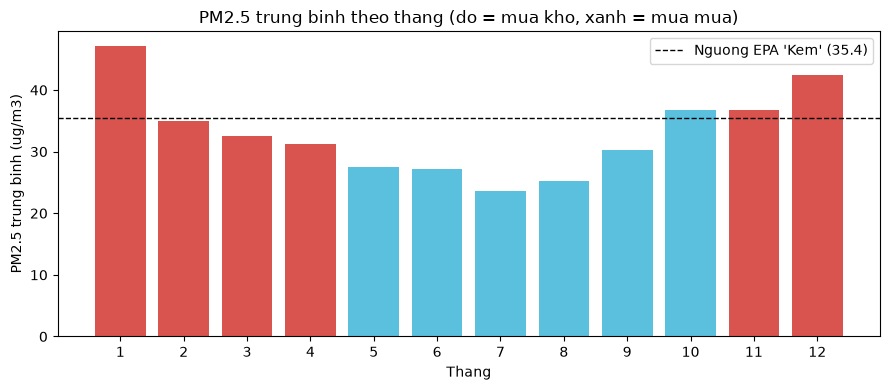

In [11]:
# groupby("month"): chia du lieu theo tung thang (1-12), tinh mean rieng cho moi thang
theo_thang = df.groupby("month")["pm25"].agg(["mean", "std", "count"]).round(2)
theo_thang.columns = ["PM25_TB", "PM25_Std", "So_ngay"]
print("PM2.5 TRUNG BINH THEO THANG")
print("-" * 50)
print(theo_thang)

# Ve bieu do cot de nhin xu huong ca nam bang mat
fig, ax = plt.subplots(figsize=(9, 4))
mau = ["#d9534f" if m in [11, 12, 1, 2, 3, 4] else "#5bc0de" for m in theo_thang.index]  # do=mua kho, xanh=mua mua
ax.bar(theo_thang.index, theo_thang["PM25_TB"], color=mau)
ax.axhline(35.4, color="black", linestyle="--", linewidth=1, label="Nguong EPA 'Kem' (35.4)")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Thang")
ax.set_ylabel("PM2.5 trung binh (ug/m3)")
ax.set_title("PM2.5 trung binh theo thang (do = mua kho, xanh = mua mua)")
ax.legend()
plt.tight_layout()
plt.savefig("../01_Data/bieu_do_pm25_theo_thang.png", dpi=120)
plt.show()

### 💡 Insight — tháng nào đỉnh điểm, khuyến nghị cụ thể theo ngành

In [12]:
print("INSIGHT - THANG NAO DINH DIEM")
print("-" * 60)

thang_cao_nhat = theo_thang["PM25_TB"].idxmax()
thang_thap_nhat = theo_thang["PM25_TB"].idxmin()
print(f"Thang o nhiem NANG NHAT : Thang {thang_cao_nhat} "
      f"(TB {theo_thang.loc[thang_cao_nhat, 'PM25_TB']:.1f} ug/m3)")
print(f"Thang o nhiem NHE NHAT  : Thang {thang_thap_nhat} "
      f"(TB {theo_thang.loc[thang_thap_nhat, 'PM25_TB']:.1f} ug/m3)")
print()
print("=> Khuyen nghi cu the cho tung nganh:")
print(f"   - Du lich / su kien ngoai troi: can trong khi len lich vao Thang {thang_cao_nhat}")
print(f"   - Y te: tang cuong truyen thong benh ho hap truoc va trong Thang {thang_cao_nhat}")
print(f"   - Ban SP bao ve ho hap (khau trang, may loc khong khi): day manh")
print(f"     chien dich ban hang TRUOC Thang {thang_cao_nhat} (chuan bi som cho khach hang)")

INSIGHT - THANG NAO DINH DIEM
------------------------------------------------------------
Thang o nhiem NANG NHAT : Thang 1 (TB 47.2 ug/m3)
Thang o nhiem NHE NHAT  : Thang 7 (TB 23.5 ug/m3)

=> Khuyen nghi cu the cho tung nganh:
   - Du lich / su kien ngoai troi: can trong khi len lich vao Thang 1
   - Y te: tang cuong truyen thong benh ho hap truoc va trong Thang 1
   - Ban SP bao ve ho hap (khau trang, may loc khong khi): day manh
     chien dich ban hang TRUOC Thang 1 (chuan bi som cho khach hang)


## 6. Bảng tổng hợp toàn bộ biến số — lưu lại cho báo cáo

Tính cùng lúc mean/median/std/CV/skewness/kurtosis cho **PM2.5 + 6 biến X** (`temperature`, `humidity`, `wind`, `rain`, `pbl_sang_m`, `ap_suat`) thay vì làm tay từng cột — đây là bảng đưa thẳng vào báo cáo mục "Thống kê mô tả".

*(2 biến `pbl_sang_m`, `ap_suat` mới thêm sau khi test hồi quy ở notebook 03 cho thấy có ích — bổ sung vào đây để thống kê mô tả cũng phủ đủ các biến chính thức dùng trong mô hình.)*

In [13]:
bien_can_thong_ke = ["pm25", "temperature", "humidity", "wind", "rain", "pbl_sang_m", "ap_suat"]

ket_qua = []
for ten in bien_can_thong_ke:
    x = df[ten]
    ket_qua.append({
        "Bien": ten,
        "Mean": round(x.mean(), 2),
        "Median": round(x.median(), 2),
        "Std": round(x.std(), 2),
        "CV (%)": round(x.std() / x.mean() * 100, 1),
        "Skewness": round(stats.skew(x), 3),
        "Kurtosis": round(stats.kurtosis(x), 3),
        "Min": round(x.min(), 2),
        "Max": round(x.max(), 2),
    })

bang_tk = pd.DataFrame(ket_qua)
bang_tk.to_csv("../01_Data/bang_thong_ke_mo_ta.csv", index=False)
print("Da luu: ../01_Data/bang_thong_ke_mo_ta.csv")
bang_tk

Da luu: ../01_Data/bang_thong_ke_mo_ta.csv


,Bien,Mean,Median,Std,CV (%),Skewness,Kurtosis,Min,Max
0,pm25,32.41,30.30,11.40,35.2,1.140,2.011,12.90,92.80
1,temperature,29.09,29.00,1.27,4.4,0.507,0.347,26.20,34.10
2,humidity,54.70,54.70,6.02,11.0,-0.222,-0.296,38.50,69.50
3,wind,13.39,13.20,3.32,24.8,0.394,-0.055,4.40,23.40
4,rain,5.95,2.00,7.94,133.6,1.758,3.216,0.00,45.90
5,pbl_sang_m,246.25,197.86,166.15,67.5,0.885,0.069,17.86,832.86
6,ap_suat,1008.71,1008.60,1.85,0.2,0.398,0.205,1003.80,1014.10


### 💡 Insight — biến nào biến động mạnh nhất (gợi mở câu ③)

In [14]:
print("INSIGHT - BIEN NAO BIEN DONG MANH NHAT")
print("-" * 60)

bien_bien_dong = bang_tk.loc[bang_tk["CV (%)"].idxmax(), "Bien"]
cv_max = bang_tk["CV (%)"].max()
print(f"Bien co CV (he so bien thien) cao nhat: {bien_bien_dong} (CV = {cv_max:.1f}%)")
print(f"=> Bien nay dao dong manh nhat giua cac ngay -> la ung vien dang chu y")
print(f"   khi tim nhan to anh huong PM2.5 manh nhat o cau hoi (3) - hoi quy o GD3")
print(f"   (Luu y: CV cao khong dong nghia anh huong manh den PM2.5 - phai cho")
print(f"   he so hoi quy + VIF o GD3 moi ket luan chac chan duoc)")

INSIGHT - BIEN NAO BIEN DONG MANH NHAT
------------------------------------------------------------
Bien co CV (he so bien thien) cao nhat: rain (CV = 133.6%)
=> Bien nay dao dong manh nhat giua cac ngay -> la ung vien dang chu y
   khi tim nhan to anh huong PM2.5 manh nhat o cau hoi (3) - hoi quy o GD3
   (Luu y: CV cao khong dong nghia anh huong manh den PM2.5 - phai cho
   he so hoi quy + VIF o GD3 moi ket luan chac chan duoc)


## 7. TÓM TẮT — GĐ 2 đã trả lời được gì cho câu hỏi kinh doanh

Gộp lại toàn bộ insight rải rác ở trên thành 1 bảng tổng kết, đúng những gì sẽ trình bày/trả lời khi thầy hỏi.

In [15]:
print("=" * 62)
print(" TOM TAT: GD2 TRA LOI DUOC GI CHO CAU HOI KINH DOANH ".center(62, "="))
print("=" * 62)
print(f"1. {can_canh_bao:.1f}% so ngay trong nam o muc CAN CANH BAO (Kem tro len)")
print(f"2. Mua kho o nhiem nang hon mua mua {lech_mua:.0f}%")
print(f"3. Thang o nhiem nang nhat: Thang {thang_cao_nhat}")
print(f"4. Bien thoi tiet bien dong manh nhat: {bien_bien_dong} (goi mo cau hoi 3)")
print()
print("KHUYEN NGHI cho cac don vi chiu anh huong:")
print(f"  - Su kien ngoai troi / du lich : tranh len lich cao diem vao Thang {thang_cao_nhat}")
print( "                                    va toan bo mua kho noi chung")
print( "  - Y te                        : chuan bi nguon luc ho hap tang cuong")
print(f"                                    truoc va trong Thang {thang_cao_nhat}")
print(f"  - Ban SP bao ve ho hap         : day manh chien dich TRUOC Thang {thang_cao_nhat}")
print()
print("LUU Y QUAN TRONG: day moi la ket luan tu THONG KE MO TA (quan sat xu huong).")
print("Cau hoi (2) va (3) o GD3 se KIEM DINH xem cac khac biet nay co Y NGHIA")
print("THONG KE that (khong phai ngau nhien) hay khong, va tim CHINH XAC nhan to")
print("nao anh huong PM2.5 manh nhat bang hoi quy (khong chi doan qua CV).")

==== TOM TAT: GD2 TRA LOI DUOC GI CHO CAU HOI KINH DOANH =====
1. 32.1% so ngay trong nam o muc CAN CANH BAO (Kem tro len)
2. Mua kho o nhiem nang hon mua mua 35%
3. Thang o nhiem nang nhat: Thang 1
4. Bien thoi tiet bien dong manh nhat: rain (goi mo cau hoi 3)

KHUYEN NGHI cho cac don vi chiu anh huong:
  - Su kien ngoai troi / du lich : tranh len lich cao diem vao Thang 1
                                    va toan bo mua kho noi chung
  - Y te                        : chuan bi nguon luc ho hap tang cuong
                                    truoc va trong Thang 1
  - Ban SP bao ve ho hap         : day manh chien dich TRUOC Thang 1

LUU Y QUAN TRONG: day moi la ket luan tu THONG KE MO TA (quan sat xu huong).
Cau hoi (2) va (3) o GD3 se KIEM DINH xem cac khac biet nay co Y NGHIA
THONG KE that (khong phai ngau nhien) hay khong, va tim CHINH XAC nhan to
nao anh huong PM2.5 manh nhat bang hoi quy (khong chi doan qua CV).
